# Falla estàtica: disseny paramètric d'un suport corbat
**Disseny i assaig de màquines** · Màster en Enginyeria Industrial (UdG)

Cas d'estudi: suport en U amb perfil en I sotmès a la força d'un cilindre pneumàtic.

- **Apartats 1) i 2):** tensions als punts crítics i factor de seguretat estàtic amb $t = 4$ mm i $F = 3000$ N, considerant el comportament de biga corba i de biga recta.
- **Apartat 3):** gruix $t$ necessari per a $F = 2000$ N amb el mateix factor de seguretat (mètode de la bisecció).
- **Apartat 4):** gruix $t$ per a diverses forces $F$.

Aquest quadern reprodueix l'script `DiAM_estatic_04b_SOL.py` i té la mateixa estructura que `DiAM_estatic_04b_SOL.m`.

In [1]:
import math
import numpy as np
import matplotlib.pyplot as plt

## Funcions emprades
- `f_curved_beam_I`: propietats de la secció en I (Taula 2): $A$, $I$, $r_c$ i $r_n$.
- `DiAM_f_beam_I`: sol·licitacions (Taula 3), tensions als punts 'a', 'b', 'c' i 'd' (Taula 4) i factor de seguretat estàtic (Taula 6). Amb `fig=1` dibuixa la distribució de tensions de la Taula 5.
- `biseccio`: mètode de la bisecció (Algorisme 1). Retorna el gruix arrodonit amunt a la resolució `inc`.

In [2]:
# (en Python s'han de definir abans de cridar-les; en MatLab van al final)

def f_curved_beam_I(r_i, r_o, t, t_i, t_o, b_i, b_o):
    """Propietats de la secció en I (Taula 2).
    Entrada: r_i, r_o, t, t_i, t_o, b_i, b_o (segons figura secció) [mm]
    Sortida: radi centroide r_c, radi línia neutra r_n [mm],
             àrea A [mm^2] i moment de segon ordre I [mm^4]
    """
    h = r_o - r_i                                         # cantell
    A = h*t + t_i*(b_i - t) + t_o*(b_o - t)               # àrea
    r_c = r_i + (0.5*h**2*t + 0.5*t_i**2*(b_i - t)
                 + t_o*(b_o - t)*(h - t_o/2)) / A         # radi centroide
    r_n = A / (b_i*math.log((r_i + t)/r_i)
               + t*math.log((r_o - t_o)/(r_i + t_i))
               + b_o*math.log(r_o/(r_o - t_o)))           # radi línia neutra
    I = (h**3*t/12         + h*t*(r_c - r_i - h/2)**2
         + t_i**3*(b_i - t)/12 + t_i*(b_i - t)*(r_c - r_i - t_i/2)**2
         + t_o**3*(b_o - t)/12 + t_o*(b_o - t)*(r_c - r_i - h + t_o/2)**2)
    return r_c, r_n, A, I


def DiAM_f_beam_I(F, d, r_i, r_o, t, b_i, b_o, Sy, fig=0):
    """Tensions als punts a, b, c, d i factor de seguretat estàtic (Taules 2-6).
    Entrada: F [N], geometria [mm], gruix t [mm], Sy [MPa]
             fig=1 dibuixa les tensions a la secció, fig=0 no ho fa
    Sortida: SFe, factor de seguretat estàtic de la secció [-]
             R,   diccionari amb resultats intermedis
    """
    # Propietats de la secció de perfil en I (t_i = t_o = t)
    r_c, r_n, A, I = f_curved_beam_I(r_i, r_o, t, t, t, b_i, b_o)
    e   = r_c - r_n
    c_i = r_n - r_i
    c_o = r_o - r_n
    y_i = r_c - r_i
    y_o = r_o - r_c

    # Sol·licitacions a la secció crítica (Taula 3)
    N = F                     # N,    força axial
    M = (d + y_i)*F           # N·mm, moment flector

    # Tensions als 4 punts crítics (Taula 4) [MPa]
    #   'a' superior i 'b' inferior: hipòtesi biga corba
    #   'c' superior i 'd' inferior: hipòtesi biga recta
    sig_a = N/A + M*c_i/(A*e*r_i)
    sig_b = N/A - M*c_o/(A*e*r_o)
    sig_c = N/A + M*y_i/I
    sig_d = N/A - M*y_o/I
    sigma = np.array([sig_a, sig_b, sig_c, sig_d])

    # Factor de seguretat estàtic (Taula 6)
    SF = Sy/np.abs(sigma)
    SFe = float(np.min(SF))

    R = dict(h=r_o - r_i, A=A, I=I, r_c=r_c, r_n=r_n, e=e, N=N, M=M,
             sigma=sigma, SF=SF)

    # Distribució de tensions a la secció crítica (Taula 5)
    if fig == 1:
        r_ = np.arange(r_i, r_o + 1e-9, 0.1)
        sigma_rect = N/A + M*(r_c - r_)/I
        sigma_corb = N/A + M*(r_n - r_)/(A*e*r_)
        plt.figure()
        plt.grid(True)
        plt.plot(sigma_corb, -r_, linewidth=2.0, label=r'$\sigma$ biga corba')
        plt.plot(sigma_rect, -r_, 'r', linewidth=2.0, label=r'$\sigma$ biga recta')
        plt.plot([-400, 400], [-r_n, -r_n], '--b', linewidth=1.2, label=r'$r_n$')
        plt.plot([-400, 400], [-r_c, -r_c], '--r', linewidth=1.2, label=r'$r_c$')
        plt.plot(sigma, [-r_i, -r_o, -r_i, -r_o], 'ok', markersize=8,
                 markerfacecolor='none', markeredgewidth=2.0)
        plt.legend(loc='best')
        plt.xlabel(r'$\sigma$ [MPa]')
        plt.ylabel(r'$r$ [mm]')
        plt.show()

    return SFe, R


def biseccio(F, SF_d, d, r_i, r_o, b_i, b_o, Sy, t_min, t_max, SF_eps, inc):
    """Mètode de la bisecció (Algorisme 1).
    Retorna el gruix arrodonit amunt a la resolució inc, el nombre
    d'iteracions i el SF obtingut amb aquest gruix arrodonit.
    """
    SF_trial = 0.0
    cont = 0
    t = 0.0
    while abs(SF_d - SF_trial) > SF_eps:      # repeteix fins a convergir
        cont += 1
        t = (t_min + t_max)/2                 # punt mig de l'interval
        SF_trial, _ = DiAM_f_beam_I(F, d, r_i, r_o, t, b_i, b_o, Sy)
        if SF_d >= SF_trial:
            t_min = t                         # cal més gruix
        else:
            t_max = t                         # sobra gruix
    t_inc = math.ceil(t/inc - 1e-9)*inc       # arrodonit amunt a inc
    SF_inc, _ = DiAM_f_beam_I(F, d, r_i, r_o, t_inc, b_i, b_o, Sy)
    return t_inc, cont, SF_inc

## Dades del problema
Especificacions de les Taules 1, 8 i 9 de l'enunciat.

In [3]:
# Geometria [mm]
d   = 80.0      # distància de la força a la part interior U
r_i = 40.0      # radi interior suport U
r_o = 64.0      # radi exterior suport U
b_i = 20.0      # amplada ala interior secció I
b_o = 10.0      # amplada ala exterior secció I
t0  = 4.0       # gruix perfil secció I (disseny inicial)
# Material [MPa]
Sut = 820.0     # resistència última a tracció
Sy  = 600.0     # límit de fluència
# Càrregues [N]
F0 = 3000.0                                 # apartats 1) i 2)
F3 = 2000.0                                 # apartat 3)
F4 = np.array([1600., 2000., 2400., 2800., 3200.])   # apartat 4)
# Paràmetres del mètode de la bisecció
t_min0 = 0.5    # mm, gruix mínim de l'interval inicial
t_max0 = 10.0   # mm, gruix màxim de l'interval inicial
SF_eps = 5e-3   # tolerància pel factor de seguretat
inc    = 0.1    # mm, resolució de fabricació del gruix

## Apartats 1) i 2): disseny inicial
Distribució de tensions a la secció crítica amb les hipòtesis de biga corba i de biga recta, i factor de seguretat de la secció. Aquest factor de seguretat és el que s'imposa en el redisseny.

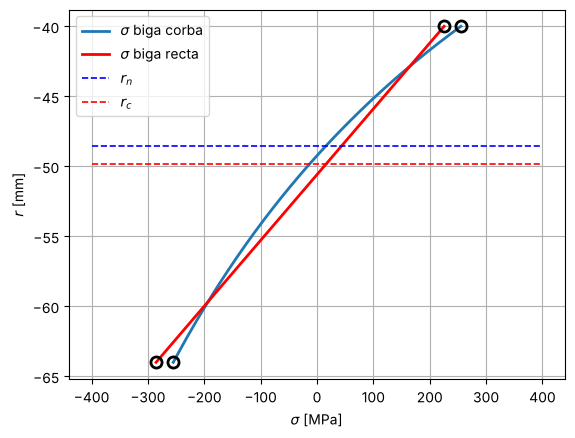

Apartats 1) i 2): F = 3000 N i t = 4.0 mm
  A = 184 mm^2, I = 12656 mm^4, r_c = 49.83 mm, r_n = 48.52 mm, e = 1.31 mm
  N = 3000 N, M = 269478 N·mm
  punt a: sigma =   255.3 MPa, SF = 2.35
  punt b: sigma =  -255.0 MPa, SF = 2.35
  punt c: sigma =   225.5 MPa, SF = 2.66
  punt d: sigma =  -285.5 MPa, SF = 2.10
  SF de la secció = 2.10



In [4]:
SF_d, R1 = DiAM_f_beam_I(F0, d, r_i, r_o, t0, b_i, b_o, Sy, fig=1)

print(f"Apartats 1) i 2): F = {F0:.0f} N i t = {t0:.1f} mm")
print(f"  A = {R1['A']:.0f} mm^2, I = {R1['I']:.0f} mm^4, "
      f"r_c = {R1['r_c']:.2f} mm, r_n = {R1['r_n']:.2f} mm, e = {R1['e']:.2f} mm")
print(f"  N = {R1['N']:.0f} N, M = {R1['M']:.0f} N·mm")
for k, p in enumerate('abcd'):
    print(f"  punt {p}: sigma = {R1['sigma'][k]:7.1f} MPa, SF = {R1['SF'][k]:.2f}")
print(f"  SF de la secció = {SF_d:.2f}\n")

## Apartat 3): redisseny per a $F = 2000$ N
Es busca el gruix $t$ que dona el mateix factor de seguretat que l'apartat 1) amb el mètode de la bisecció.

In [5]:
t3, n3, SF3 = biseccio(F3, SF_d, d, r_i, r_o, b_i, b_o, Sy,
                       t_min0, t_max0, SF_eps, inc)
print(f"Apartat 3): amb F = {F3:.0f} N, {n3} iteracions, "
      f"t = {t3:.1f} mm i SF = {SF3:.2f}\n")

Apartat 3): amb F = 2000 N, 9 iteracions, t = 2.1 mm i SF = 2.12



## Apartat 4): redisseny per a diverses forces
Es repeteix la bisecció per a cada força. Com a comprovació, també s'aplica el mètode incremental, que augmenta $t$ en passos de `inc` fins a arribar al factor de seguretat desitjat.

In [6]:
t4  = np.zeros_like(F4)
n4  = np.zeros(len(F4), dtype=int)
SF4 = np.zeros_like(F4)
print("Apartat 4): mètode de la bisecció")
for k, F in enumerate(F4):
    t4[k], n4[k], SF4[k] = biseccio(F, SF_d, d, r_i, r_o, b_i, b_o, Sy,
                                    t_min0, t_max0, SF_eps, inc)
    print(f"  F = {F:.0f} N: {n4[k]} iteracions, t = {t4[k]:.1f} mm, "
          f"SF = {SF4[k]:.2f}")

# Comprovació amb el mètode incremental (augmentar t en passos de inc)
print("\nComprovació: mètode incremental")
for F in F4:
    t = t_min0
    SF_trial, _ = DiAM_f_beam_I(F, d, r_i, r_o, t, b_i, b_o, Sy)
    cont = 0
    while SF_trial < SF_d:
        cont += 1
        t = round(t + inc, 6)   # evita errors d'arrodoniment
        SF_trial, _ = DiAM_f_beam_I(F, d, r_i, r_o, t, b_i, b_o, Sy)
    print(f"  F = {F:.0f} N: {cont} iteracions, t = {t:.1f} mm, "
          f"SF = {SF_trial:.2f}")

Apartat 4): mètode de la bisecció
  F = 1600 N: 9 iteracions, t = 1.6 mm, SF = 2.15
  F = 2000 N: 9 iteracions, t = 2.1 mm, SF = 2.12
  F = 2400 N: 9 iteracions, t = 2.8 mm, SF = 2.15
  F = 2800 N: 8 iteracions, t = 3.6 mm, SF = 2.13
  F = 3200 N: 8 iteracions, t = 4.7 mm, SF = 2.12

Comprovació: mètode incremental
  F = 1600 N: 11 iteracions, t = 1.6 mm, SF = 2.15
  F = 2000 N: 16 iteracions, t = 2.1 mm, SF = 2.12
  F = 2400 N: 23 iteracions, t = 2.8 mm, SF = 2.15
  F = 2800 N: 30 iteracions, t = 3.5 mm, SF = 2.10
  F = 3200 N: 42 iteracions, t = 4.7 mm, SF = 2.12


## Representació gràfica de l'apartat 4)

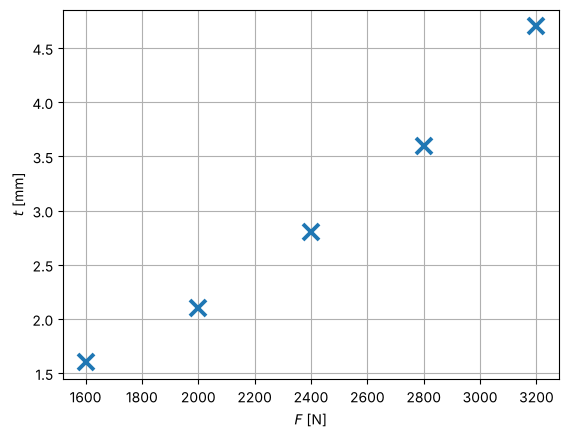

In [7]:
# La relació entre F i t no és lineal, comportament típic d'elements
# sotmesos principalment a flexió.
plt.figure()
plt.grid(True)
plt.plot(F4, t4, 'x', markersize=12, markeredgewidth=2.8)
plt.xlabel(r'$F$ [N]')
plt.ylabel(r'$t$ [mm]')
plt.show()

## Discussió
La relació entre la força $F$ i el gruix $t$ no és lineal: per a increments iguals de força, l'increment de gruix necessari és cada vegada més gran. Era d'esperar, ja que l'element està sotmès bàsicament a flexió i les propietats resistents de la secció no són proporcionals al gruix $t$.